<a href="https://colab.research.google.com/github/annjerinsundar-code/ICTAK-AI-ML-Coursework/blob/main/Supervised_Learning_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [93]:
# Libraries for working with data
import pandas as pd
import numpy as np

# Visualization tools
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Linear Regression Model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Evaluation Metrics for the model
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


#Data Exploration

In [94]:
# Load the dataset
df = pd.read_csv('/content/car details v4.csv')

# Display the first five records
df.head()

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0


In [95]:
# Display the last 5 rows
df.tail()

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
2054,Mahindra,XUV500 W8 [2015-2017],850000,2016,90300,Diesel,Manual,Surat,White,First,Individual,2179 cc,138 bhp @ 3750 rpm,330 Nm @ 1600 rpm,FWD,4585.0,1890.0,1785.0,7.0,70.0
2055,Hyundai,Eon D-Lite +,275000,2014,83000,Petrol,Manual,Ahmedabad,White,Second,Individual,814 cc,55 bhp @ 5500 rpm,75 Nm @ 4000 rpm,FWD,3495.0,1550.0,1500.0,5.0,32.0
2056,Ford,Figo Duratec Petrol ZXI 1.2,240000,2013,73000,Petrol,Manual,Thane,Silver,First,Individual,1196 cc,70 bhp @ 6250 rpm,102 Nm @ 4000 rpm,FWD,3795.0,1680.0,1427.0,5.0,45.0
2057,BMW,5-Series 520d Luxury Line [2017-2019],4290000,2018,60474,Diesel,Automatic,Coimbatore,White,First,Individual,1995 cc,188 bhp @ 4000 rpm,400 Nm @ 1750 rpm,RWD,4936.0,1868.0,1479.0,5.0,65.0
2058,Mahindra,Bolero Power Plus ZLX [2016-2019],670000,2017,72000,Diesel,Manual,Guwahati,White,First,Individual,1493 cc,70 bhp @ 3600 rpm,195 Nm @ 1400 rpm,RWD,3995.0,1745.0,1880.0,7.0,NaN


In [96]:
# Rows and Columns
print(f"No. of Rows: {df.shape[0]}")
print(f"No. of Columns: {df.shape[1]}")

# Column names
print(f"\nColumn Names: {df.columns.tolist()}\n\n")

#Column data and non-null values
df.info()

No. of Rows: 2059
No. of Columns: 20

Column Names: ['Make', 'Model', 'Price', 'Year', 'Kilometer', 'Fuel Type', 'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Engine', 'Max Power', 'Max Torque', 'Drivetrain', 'Length', 'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity']


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   object 
 1   Model               2059 non-null   object 
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   object 
 6   Transmission        2059 non-null   object 
 7   Location            2059 non-null   object 
 8   Color               2059 non-null   object 
 9   Owner               2059 non-null   object 
 10  Se

In [97]:
# Display summary statistics for numerical columns
df.describe()

,Price,Year,Kilometer,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
count,2.059000e+03,2059.000000,2.059000e+03,1995.000000,1995.000000,1995.000000,1995.000000,1946.000000
mean,1.702992e+06,2016.425449,5.422471e+04,4280.860652,1767.991980,1591.735338,5.306266,52.002210
std,2.419881e+06,3.363564,5.736172e+04,442.458507,135.265825,136.073956,0.822170,15.110198
min,4.900000e+04,1988.000000,0.000000e+00,3099.000000,1475.000000,1165.000000,2.000000,15.000000
25%,4.849990e+05,2014.000000,2.900000e+04,3985.000000,1695.000000,1485.000000,5.000000,41.250000
50%,8.250000e+05,2017.000000,5.000000e+04,4370.000000,1770.000000,1545.000000,5.000000,50.000000
75%,1.925000e+06,2019.000000,7.200000e+04,4629.000000,1831.500000,1675.000000,5.000000,60.000000
max,3.500000e+07,2022.000000,2.000000e+06,5569.000000,2220.000000,1995.000000,8.000000,105.000000


In [98]:
# Count missing values in each column
print(f"Missing values in each column:\n{df.isnull().sum()}")

# Count total number of missing values
print(f"\nTotal missing values: {df.isnull().sum().sum()}")

Missing values in each column:
Make                    0
Model                   0
Price                   0
Year                    0
Kilometer               0
Fuel Type               0
Transmission            0
Location                0
Color                   0
Owner                   0
Seller Type             0
Engine                 80
Max Power              80
Max Torque             80
Drivetrain            136
Length                 64
Width                  64
Height                 64
Seating Capacity       64
Fuel Tank Capacity    113
dtype: int64

Total missing values: 745


In [99]:
# Check for duplicate rows
print(f"Number of duplicate rows: {df.duplicated().sum()}")

Number of duplicate rows: 0


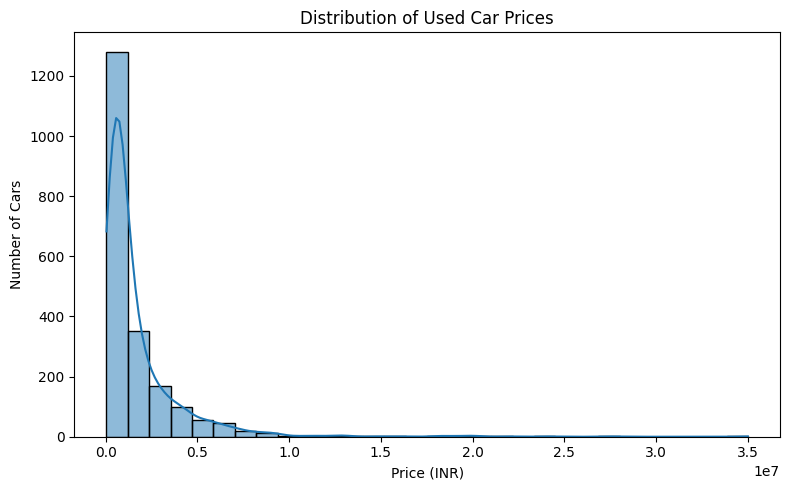

In [100]:
# Plot the distribution of car prices using Seaborn
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Price", bins=30, kde = True)
plt.title("Distribution of Used Car Prices")
plt.xlabel("Price (INR)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

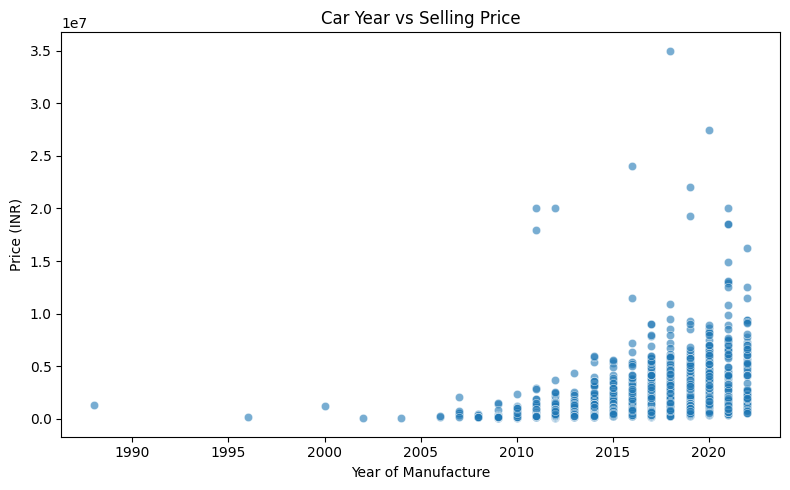

In [101]:
# Explore the relationship between year of manufacture and price using Seaborn
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Year", y="Price", alpha=0.6)
plt.title("Car Year vs Selling Price")
plt.xlabel("Year of Manufacture")
plt.ylabel("Price (INR)")
plt.tight_layout()
plt.show()

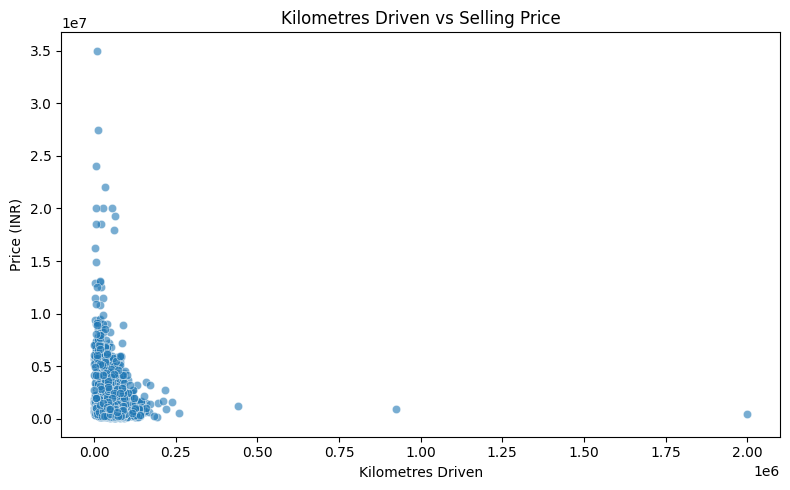

In [102]:
# Explore the relationship between kilometres driven and price using Seaborn
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Kilometer", y="Price", alpha=0.6)
plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Price (INR)")
plt.tight_layout()
plt.show()

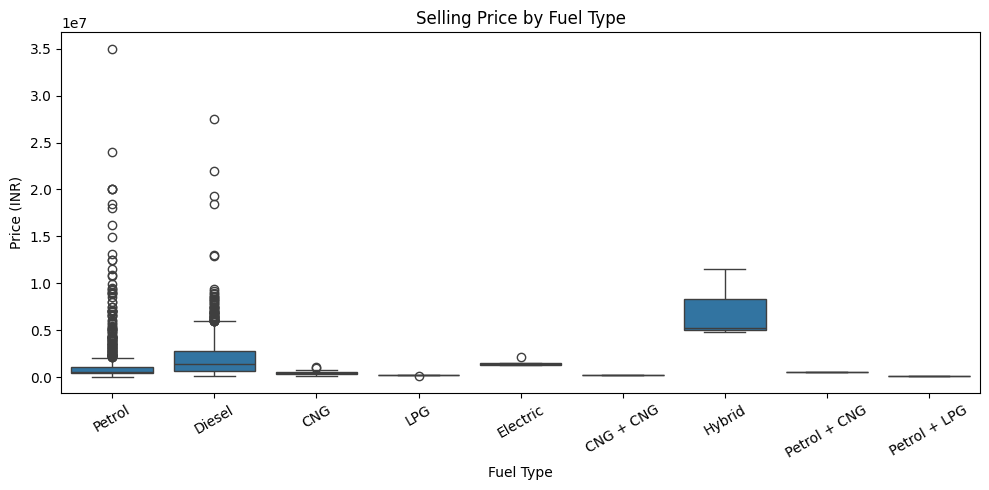

In [103]:
# Compare prices across fuel types using a Seaborn boxplot
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Fuel Type", y="Price")
plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Price (INR)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

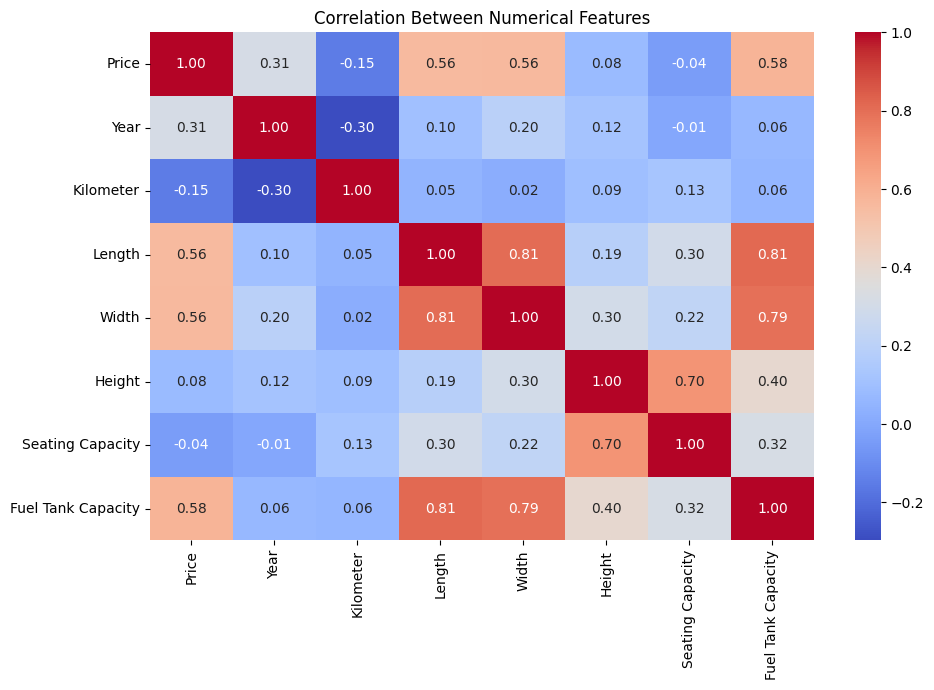

In [104]:
# Calculate and visualise correlations between numerical columns
correlation = df.select_dtypes(include="number").corr()
plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

# Data Preprocessing

In [105]:
# Make a copy so the original DataFrame remains unchanged
df_copy = df.copy()

# Remove duplicate rows, if any
df = df.drop_duplicates()

# Separate the target variable
y = df["Price"]

# Separate the input features
x = df.drop("Price", axis=1)

print("Number of rows after removing duplicates:", len(df))
print("Number of input features:", X.shape[1])

Number of rows after removing duplicates: 2059
Number of input features: 19


In [106]:
# Identify numerical and categorical input columns
numeric_features = x.select_dtypes(include="number").columns
categorical_features = x.select_dtypes(exclude="number").columns

print("Numerical features:")
print(list(numeric_features))

print("\nCategorical features:")
print(list(categorical_features))

Numerical features:
['Year', 'Kilometer', 'Length', 'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity']

Categorical features:
['Make', 'Model', 'Fuel Type', 'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Engine', 'Max Power', 'Max Torque', 'Drivetrain']


In [107]:
# Create a preprocessing pipeline for numerical columns
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Create a preprocessing pipeline for categorical columns
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply each pipeline to the appropriate columns
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing steps created successfully.")

Preprocessing steps created successfully.


#Model Development

In [108]:
# Split the data into training and testing sets
# 80% is used for training and 20% for testing
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

print("Training rows:", x_train.shape[0])
print("Testing rows:", x_test.shape[0])

Training rows: 1647
Testing rows: 412


In [109]:
# Create a pipeline that preprocesses the data and trains Linear Regression
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

print("Linear Regression pipeline created.")

Linear Regression pipeline created.


In [110]:
# Train the model using the training data
model.fit(x_train, y_train)

print("Model training completed.")

Model training completed.


In [111]:
# Predict prices for the test data
y_pred = model.predict(x_test)

# Display the first ten predicted prices
print("First ten predicted prices (INR):")
print(*y_pred[:10],sep="\n")

First ten predicted prices (INR):
3524675.263260077
900479.9397727987
365396.78069305513
1343084.3973118844
691503.9191076993
-10745.292604282498
1617456.3307158316
2659538.837268401
849867.7893954176
3420337.596879434


#Evaluate the model's performance

In [112]:
# Calculate the evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display the results
print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error (MAE): ",mae)
print("Mean Squared Error (MSE): ",mse)
print("Root Mean Squared Error ",rmse)
print("R-squared (R²): ",r2)

Model Evaluation Results
------------------------
Mean Absolute Error (MAE):  512651.5179350536
Mean Squared Error (MSE):  2825696174115.585
Root Mean Squared Error  1680980.7179487767
R-squared (R²):  0.5955364960064069


In [113]:
# Compare actual and predicted prices for the first ten test records
results = pd.DataFrame({
    "Actual Price (INR)": y_test.values,
    "Predicted Price (INR)": y_pred
})

results["Absolute Error (INR)"] = (
    results["Actual Price (INR)"] - results["Predicted Price (INR)"]
).abs()

results.head(10)

,Actual Price (INR),Predicted Price (INR),Absolute Error (INR)
0,4800000,3.524675e+06,1.275325e+06
1,825000,9.004799e+05,7.547994e+04
2,695000,3.653968e+05,3.296032e+05
3,950000,1.343084e+06,3.930844e+05
4,819999,6.915039e+05,1.284951e+05
5,310000,-1.074529e+04,3.207453e+05
6,1000000,1.617456e+06,6.174563e+05
7,1998999,2.659539e+06,6.605398e+05
8,850000,8.498678e+05,1.322106e+02
9,3950000,3.420338e+06,5.296624e+05


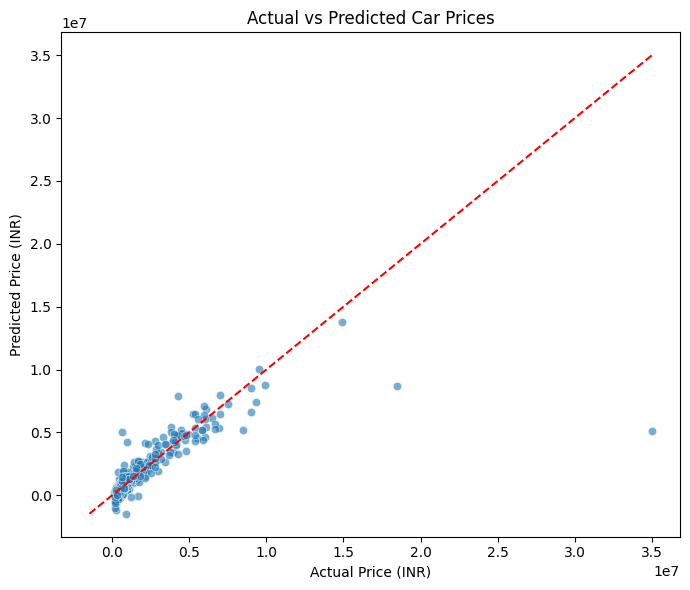

In [114]:
# Plot actual prices against predicted prices using Seaborn
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)

# Add a reference line where predictions would equal actual values
lower_limit = min(y_test.min(), y_pred.min())
upper_limit = max(y_test.max(), y_pred.max())
plt.plot([lower_limit, upper_limit], [lower_limit, upper_limit], "r--")

plt.title("Actual vs Predicted Car Prices")
plt.xlabel("Actual Price (INR)")
plt.ylabel("Predicted Price (INR)")
plt.tight_layout()
plt.show()

#Interpretation of the model's findings

In [115]:
# Interpret the R-squared score
if r2 > 0.8:
    print("The model explains a large proportion of price variation.")
elif r2 > 0.5:
    print("The model explains a moderate proportion of price variation.")
elif r2 >= 0:
    print("The model explains a limited proportion of price variation.")
else:
    print("The model performs worse than a mean-price baseline.")

The model explains a moderate proportion of price variation.


In [116]:
# Final summary of the Linear Regression model
print("USED CAR PRICE PREDICTION")
print("**************************\n")

# Display the dataset size after duplicate removal
print("Dataset size:", df.shape)

# Display the number of training records
print("Training records:", len(x_train))

# Display the number of testing records
print("Testing records:", len(x_test))

# Display the evaluation metrics
print("\n\nMODEL PERFORMANCE")
print("-----------------")
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("MAE:", round(mae, 2))
print("R-squared:", round(r2, 4))

# Display the first five actual and predicted prices
print("\n\nACTUAL VS PREDICTED PRICES")
print("--------------------------")
print(results.rename(index=lambda x: x + 1).head())


USED CAR PRICE PREDICTION
**************************

Dataset size: (2059, 20)
Training records: 1647
Testing records: 412


MODEL PERFORMANCE
-----------------
MSE: 2825696174115.58
RMSE: 1680980.72
MAE: 512651.52
R-squared: 0.5955


ACTUAL VS PREDICTED PRICES
--------------------------
   Actual Price (INR)  Predicted Price (INR)  Absolute Error (INR)
1             4800000           3.524675e+06          1.275325e+06
2              825000           9.004799e+05          7.547994e+04
3              695000           3.653968e+05          3.296032e+05
4              950000           1.343084e+06          3.930844e+05
5              819999           6.915039e+05          1.284951e+05
